Data Cleaning and Preprocessing

In [1]:
import pandas as pd 
import numpy as np
import re
import string 

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
import pandas as pd
RAW_PATH = "C:/Users/Acer/Desktop/Big_Data_Analysis_Project/Hotel_Reviews.csv"
df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)
df.head(3)

Shape: (515738, 17)


,Hotel_Address,Additional_Number_of_Scoring,Review_Date,Average_Score,Hotel_Name,Reviewer_Nationality,Negative_Review,Review_Total_Negative_Word_Counts,Total_Number_of_Reviews,Positive_Review,Review_Total_Positive_Word_Counts,Total_Number_of_Reviews_Reviewer_Has_Given,Reviewer_Score,Tags,days_since_review,lat,lng
0,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Russia,I am so angry that i made this post available...,397,1403,Only the park outside of the hotel was beauti...,11,7,2.9,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
1,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Ireland,No Negative,0,1403,No real complaints the hotel was great great ...,105,7,7.5,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
2,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/31/2017,7.7,Hotel Arena,Australia,Rooms are nice but for elderly a bit difficul...,42,1403,Location was good and staff were ok It is cut...,21,9,7.1,"[' Leisure trip ', ' Family with young childre...",3 days,52.360576,4.915968


In [3]:
print(df["Negative_Review"].head(10))

0     I am so angry that i made this post available...
1                                          No Negative
2     Rooms are nice but for elderly a bit difficul...
3     My room was dirty and I was afraid to walk ba...
4     You When I booked with your company on line y...
5     Backyard of the hotel is total mess shouldn t...
6     Cleaner did not change our sheet and duvet ev...
7     Apart from the price for the brekfast Everyth...
8     Even though the pictures show very clean room...
9     The aircondition makes so much noise and its ...
Name: Negative_Review, dtype: object


In [4]:
print((df["Negative_Review"].str.strip() == "No Negative").sum())
print(df.shape[0])

127890
515738


In [5]:
print(df.columns.tolist())
df.info()

['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 17 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   Hotel_Address                               515738 non-null  object 
 1   Additional_Number_of_Scoring                515738 non-null  int64  
 2   Review_Date                                 515738 non-null  object 
 3   Average_Score                               515738 non-null  float64
 4   Hotel_Name                                  515738 non-null  object 
 5   

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\n'No Positive' count:", (df["Positive_Review"].str.strip() == "No Positive").sum())
print("'No Negative count:", (df["Negative_Review"].str.strip() == "No Negative"). sum())


Missing values per column:
Hotel_Address                                    0
Additional_Number_of_Scoring                     0
Review_Date                                      0
Average_Score                                    0
Hotel_Name                                       0
Reviewer_Nationality                             0
Negative_Review                                  0
Review_Total_Negative_Word_Counts                0
Total_Number_of_Reviews                          0
Positive_Review                                  0
Review_Total_Positive_Word_Counts                0
Total_Number_of_Reviews_Reviewer_Has_Given       0
Reviewer_Score                                   0
Tags                                             0
days_since_review                                0
lat                                           3268
lng                                           3268
dtype: int64

'No Positive' count: 35946
'No Negative count: 127890


In [7]:
print(df.columns.tolist())
df.info()

['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 17 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   Hotel_Address                               515738 non-null  object 
 1   Additional_Number_of_Scoring                515738 non-null  int64  
 2   Review_Date                                 515738 non-null  object 
 3   Average_Score                               515738 non-null  float64
 4   Hotel_Name                                  515738 non-null  object 
 5   

In [8]:
print("Missing values per column:")
print(df.isnull().sum())

print("\n'No Positive' count:", (df["Positive_Review"].str.strip() == "No Positive").sum())
print("'No Negative' count:", (df["Negative_Review"].str.strip() == "No Negative").sum())

Missing values per column:
Hotel_Address                                    0
Additional_Number_of_Scoring                     0
Review_Date                                      0
Average_Score                                    0
Hotel_Name                                       0
Reviewer_Nationality                             0
Negative_Review                                  0
Review_Total_Negative_Word_Counts                0
Total_Number_of_Reviews                          0
Positive_Review                                  0
Review_Total_Positive_Word_Counts                0
Total_Number_of_Reviews_Reviewer_Has_Given       0
Reviewer_Score                                   0
Tags                                             0
days_since_review                                0
lat                                           3268
lng                                           3268
dtype: int64

'No Positive' count: 35946
'No Negative' count: 127890


In [9]:
df["Review_Date"] = pd.to_datetime(df["Review_Date"], errors="coerce")
print("Date range:", df["Review_Date"].min(), "to", df["Review_Date"].max())
print("Unparseable dates:", df["Review_Date"].isnull().sum())

Date range: 2015-08-04 00:00:00 to 2017-08-03 00:00:00
Unparseable dates: 0


In [10]:
def extract_country(address: str) -> str:
    if not isinstance(address, str):
        return np.nan

    known_countries = {
        "Netherlands": "Netherlands",
        "United Kingdom": "United Kingdom",
        "France": "France",
        "Spain": "Spain",
        "Italy": "Italy",
        "Austria": "Austria",
    }

    for key, val in known_countries.items():
        if address.strip().endswith(key):
            return val

    return address.strip().split()[-1]

df["Country"] = df["Hotel_Address"].apply(extract_country)

In [11]:
NO_POSITIVE = "No Positive"
NO_NEGATIVE = "No Negative"

df["has_positive_text"] = df["Positive_Review"].str.strip().ne(NO_POSITIVE) & df["Positive_Review"].notnull()
df["has_negative_text"] = df["Negative_Review"].str.strip().ne(NO_NEGATIVE) & df["Negative_Review"].notnull()


In [12]:
positive_rows = df.loc[df["has_positive_text"],[
    "Hotel_Name", "Country", "Review_Date", "Reviewer_Score",
    "Reviewer_Nationality", "Positive_Review"
]].copy()
positive_rows = positive_rows.rename(columns={"Positive_Review": "review_text"})
positive_rows["sentiment"] = "positive"

In [13]:
negative_rows = df.loc[df["has_negative_text"],[
    "Hotel_Name", "Country", "Review_Date", "Reviewer_Score",
    "Reviewer_Nationality", "Negative_Review"
]].copy()
negative_rows = negative_rows.rename(columns={"Negative_Review": "review_text"})
negative_rows["sentiment"] = "negative"

In [14]:
labelled_df = pd.concat([positive_rows, negative_rows], ignore_index=True)

In [15]:
print(labelled_df.groupby("sentiment")["Reviewer_Score"].describe())

              count      mean       std  min  25%  50%  75%   max
sentiment                                                        
negative   387848.0  8.084007  1.701524  2.5  7.1  8.3  9.6  10.0
positive   479792.0  8.508087  1.554676  2.5  7.5  9.2  9.6  10.0


In [16]:
pip install nltk


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""

    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    return " ".join(tokens)


In [18]:
print(df["has_negative_text"].value_counts())

has_negative_text
True     387848
False    127890
Name: count, dtype: int64


In [19]:
print(negative_rows.shape)
negative_rows.head()

(387848, 7)


,Hotel_Name,Country,Review_Date,Reviewer_Score,Reviewer_Nationality,review_text,sentiment
0,Hotel Arena,Netherlands,2017-08-03,2.9,Russia,I am so angry that i made this post available...,negative
2,Hotel Arena,Netherlands,2017-07-31,7.1,Australia,Rooms are nice but for elderly a bit difficul...,negative
3,Hotel Arena,Netherlands,2017-07-31,3.8,United Kingdom,My room was dirty and I was afraid to walk ba...,negative
4,Hotel Arena,Netherlands,2017-07-24,6.7,New Zealand,You When I booked with your company on line y...,negative
5,Hotel Arena,Netherlands,2017-07-24,6.7,Poland,Backyard of the hotel is total mess shouldn t...,negative


In [20]:
print("positive_rows sentiment values:", positive_rows["sentiment"].unique())
print("negative_rows sentiment values:", negative_rows["sentiment"].unique())

positive_rows sentiment values: ['positive']
negative_rows sentiment values: ['negative']


In [21]:
labelled_df["review_text_clean"] = labelled_df["review_text"].apply(clean_text)
before = labelled_df.shape[0]
labelled_df = labelled_df[labelled_df["review_text_clean"].str.strip() != ""]
after = labelled_df.shape[0]

In [22]:
labelled_df["review_length_words"] = labelled_df["review_text"].str.split().str.len()
labelled_df["review_year"] = labelled_df["Review_Date"].dt.year
labelled_df["review_month"] = labelled_df["Review_Date"].dt.month

labelled_df.to_parquet("hotel_reviews_cleaned.parquet", index=False)
labelled_df.to_csv("hotel_reviews_cleaned1.csv", index=False)

In [23]:
import os 
print(os.getcwd())

c:\Users\Acer\Desktop\Big_Data_Analysis_Project


Exploratory Data Analysis

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [25]:
pip install seaborn 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
pip install openpyxl --user

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
labelled_df = pd.read_csv("hotel_reviews_cleaned1.csv")
print("Shape:", labelled_df.shape)
labelled_df.head(3)

Shape: (862958, 11)


,Hotel_Name,Country,Review_Date,Reviewer_Score,Reviewer_Nationality,review_text,sentiment,review_text_clean,review_length_words,review_year,review_month
0,Hotel Arena,Netherlands,2017-08-03,2.9,Russia,Only the park outside of the hotel was beauti...,positive,park outside hotel beautiful,9,2017,8
1,Hotel Arena,Netherlands,2017-08-03,7.5,Ireland,No real complaints the hotel was great great ...,positive,real complaint hotel great great location surr...,103,2017,8
2,Hotel Arena,Netherlands,2017-07-31,7.1,Australia,Location was good and staff were ok It is cut...,positive,location good staff cute hotel breakfast range...,19,2017,7


In [28]:
labelled_df["Review_Date"] = pd.to_datetime(labelled_df["Review_Date"], errors="coerce")

In [29]:
print(labelled_df.dtypes)

Hotel_Name                      object
Country                         object
Review_Date             datetime64[ns]
Reviewer_Score                 float64
Reviewer_Nationality            object
review_text                     object
sentiment                       object
review_text_clean               object
review_length_words              int64
review_year                      int64
review_month                     int64
dtype: object


In [30]:
print(labelled_df["sentiment"].value_counts())
print(labelled_df["sentiment"].value_counts(normalize=True) * 100)

sentiment
positive    478843
negative    384115
Name: count, dtype: int64
sentiment
positive    55.488564
negative    44.511436
Name: proportion, dtype: float64


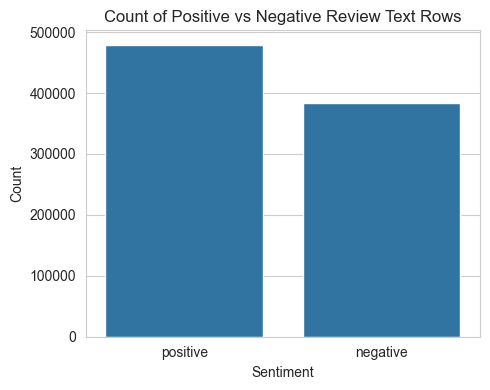

In [31]:
plt.figure(figsize=(5, 4))
sns.countplot(data=labelled_df, x="sentiment", order=["positive", "negative"])
plt.title("Count of Positive vs Negative Review Text Rows")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("eda_sentiment_balance.png", dpi=150)
plt.show()

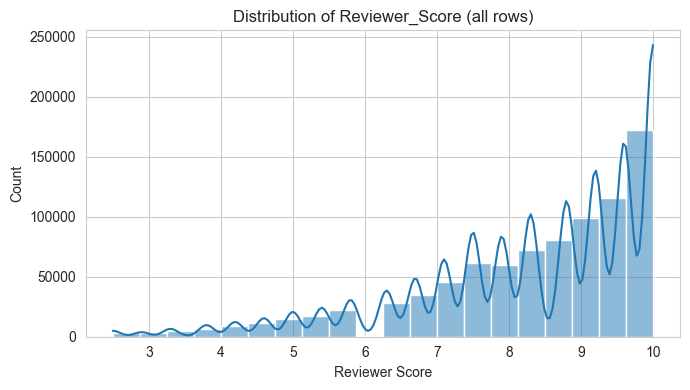

In [32]:
plt.figure(figsize=(7, 4))
sns.histplot(labelled_df["Reviewer_Score"], bins=20, kde=True)
plt.title("Distribution of Reviewer_Score (all rows)")
plt.xlabel("Reviewer Score")
plt.tight_layout()
plt.savefig("eda_score_dostribution.png", dpi=150)
plt.show()

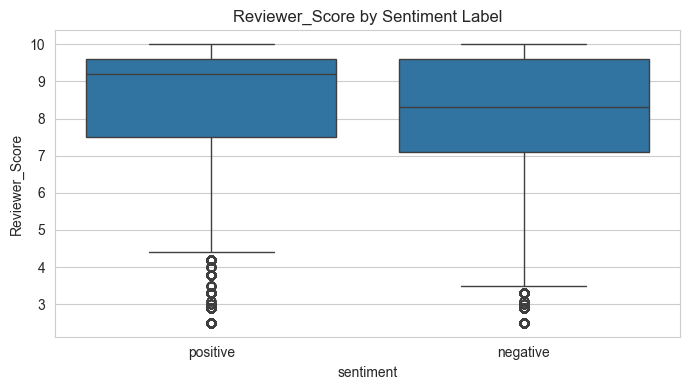

In [33]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=labelled_df, x="sentiment", y="Reviewer_Score", order=["positive", "negative"])
plt.title("Reviewer_Score by Sentiment Label")
plt.tight_layout()
plt.savefig("eda_score_by_sentiment.png", dpi=150)
plt.show()

In [34]:
print(labelled_df.groupby("sentiment")["review_length_words"].describe())

              count       mean        std  min  25%   50%   75%    max
sentiment                                                             
negative   384115.0  23.284680  31.894782  1.0  6.0  13.0  28.0  406.0
positive   478843.0  17.581901  21.879430  1.0  5.0  11.0  22.0  393.0


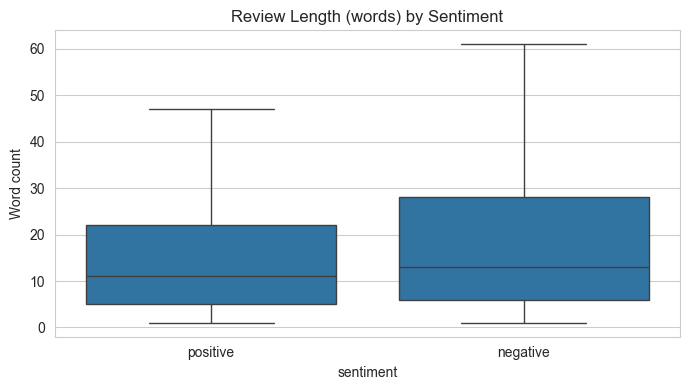

In [35]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=labelled_df, x="sentiment", y="review_length_words",
            order=["positive", "negative"], showfliers=False)
plt.title("Review Length (words) by Sentiment")
plt.ylabel("Word count")
plt.tight_layout()
plt.savefig("eda_length_by_sentiment.png", dpi=150)
plt.show()

Top 15 countries by number of review-text rows:
Country
United Kingdom    442357
Spain             100283
France             98905
Netherlands        95847
Austria            64044
Italy              61522
Name: count, dtype: int64


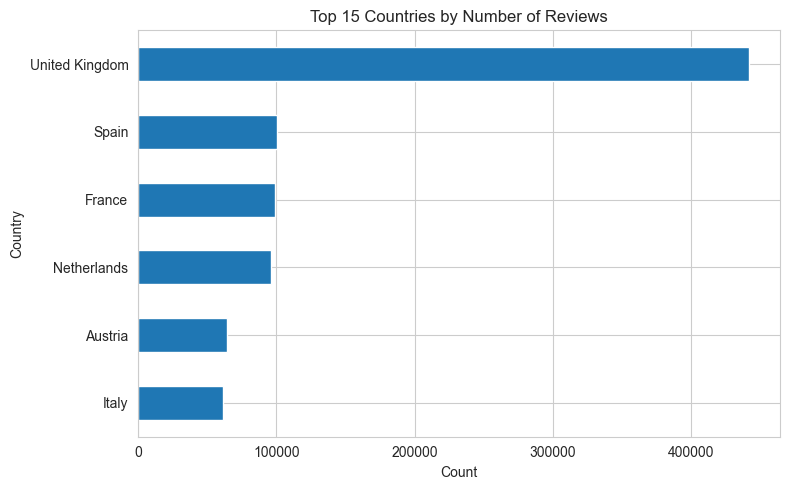

In [36]:
print("Top 15 countries by number of review-text rows:")
print(labelled_df["Country"].value_counts().head(15))

plt.figure(figsize=(8, 5))
labelled_df["Country"].value_counts().head(15).plot(kind = "barh")
plt.gca().invert_yaxis()
plt.title("Top 15 Countries by Number of Reviews")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig("eda_reviews_by_country.png", dpi=150)
plt.show()

In [37]:
print("Number 0f unique hotels:", labelled_df["Hotel_Name"].nunique())
print("\nTop 10 hotels by number of reviews:")
print(labelled_df["Hotel_Name"].value_counts().head(10))

Number 0f unique hotels: 1492

Top 10 hotels by number of reviews:
Hotel_Name
Britannia International Hotel Canary Wharf           8311
Strand Palace Hotel                                  7295
Park Plaza Westminster Bridge London                 7038
Copthorne Tara Hotel London Kensington               6094
DoubleTree by Hilton Hotel London Tower of London    5355
Grand Royale London Hyde Park                        5130
Holiday Inn London Kensington                        4837
Hilton London Metropole                              4527
Millennium Gloucester Hotel London                   4401
Intercontinental London The O2                       4238
Name: count, dtype: int64


Top 15 reviewer nationalities:
Reviewer_Nationality
United Kingdom               413452
United States of America      58356
Australia                     36035
Ireland                       24838
United Arab Emirates          17585
Saudi Arabia                  15547
Netherlands                   14810
Switzerland                   14510
Germany                       13172
Canada                        13155
France                        12027
Israel                        10635
Belgium                       10000
Italy                          9946
Turkey                         9018
Name: count, dtype: int64


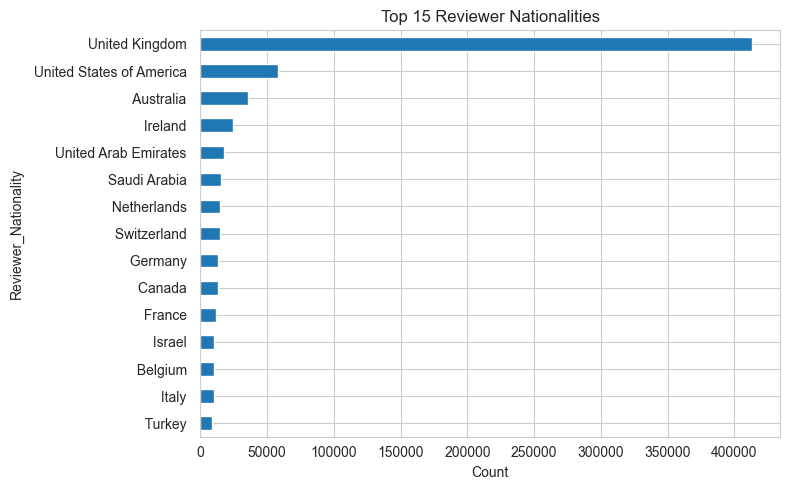

In [38]:
print("Top 15 reviewer nationalities:")
print(labelled_df["Reviewer_Nationality"].value_counts().head(15))

plt.figure(figsize=(8, 5))
labelled_df["Reviewer_Nationality"].value_counts().head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 15 Reviewer Nationalities")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig("eda_top_nationalities.png", dpi=150)
plt.show()

In [39]:
reviews_per_month = (
    labelled_df
    .groupby(["review_year", "review_month"])
    .size()
    .reset_index(name="count")
)

reviews_per_month["year_month"] = pd.to_datetime(
    reviews_per_month["review_year"].astype(str) + "-" +
    reviews_per_month["review_month"].astype(str) + "-01" 
)

reviews_per_month = reviews_per_month.sort_values("year_month")


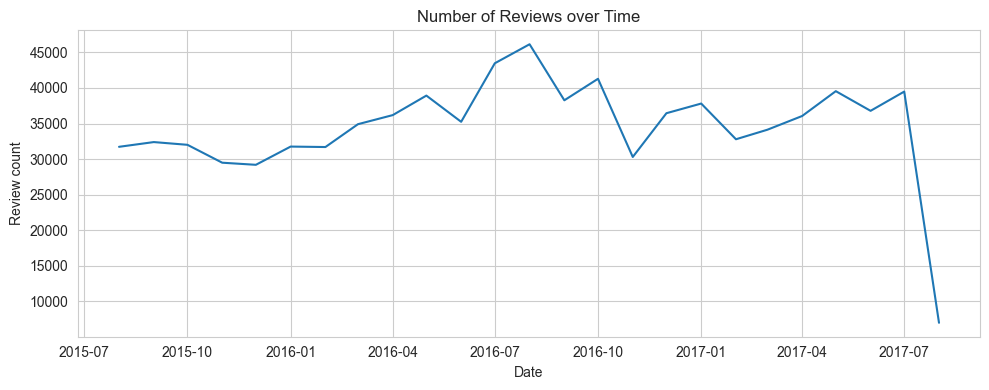

In [40]:
plt.figure(figsize=(10, 4))
plt.plot(reviews_per_month["year_month"], reviews_per_month["count"])
plt.title("Number of Reviews over Time")
plt.xlabel("Date")
plt.ylabel("Review count")
plt.tight_layout()
plt.savefig("eda_reviews_over_time.png", dpi=150)
plt.show()

In [41]:
pip install wordcloud --user

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
from wordcloud import WordCloud

positive_text = " ".join(
    labelled_df.loc[labelled_df["sentiment"] == "positive", "review_text_clean"]
    .sample(50000, random_state=42)
)

negative_text = " ".join(
    labelled_df.loc[labelled_df["sentiment"] == "negative", "review_text_clean"]
    .sample(50000, random_state=42)
)

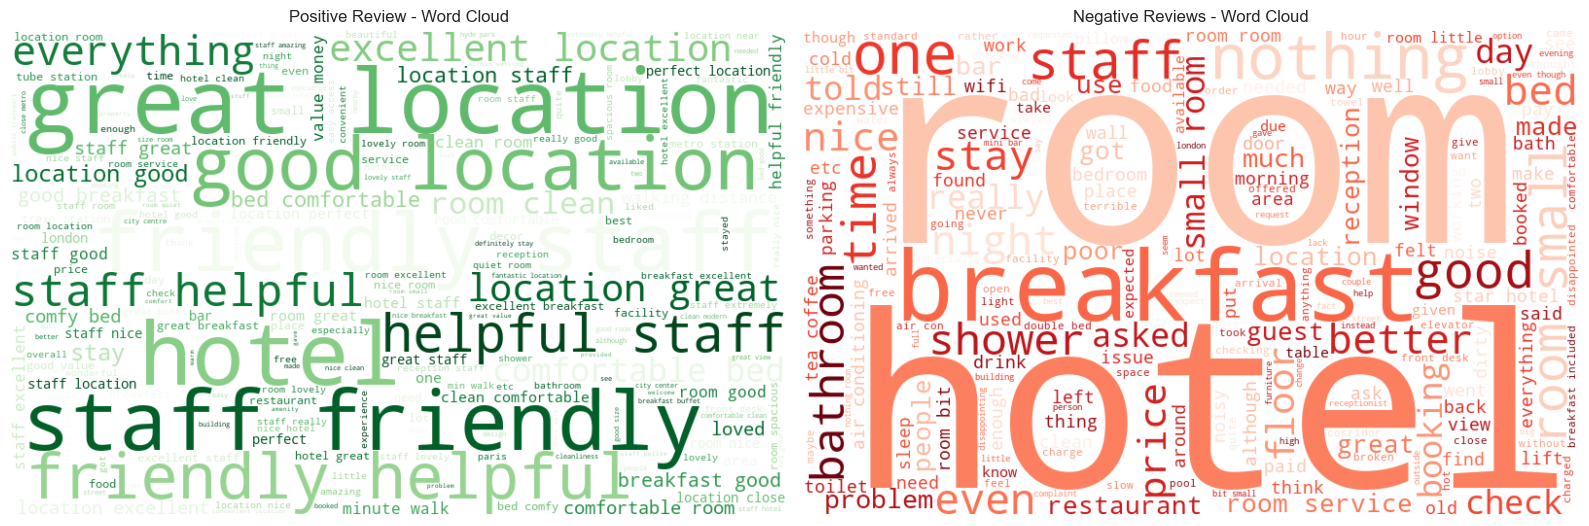

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_pos = WordCloud(width=800, height=500, background_color="white",
                   colormap="Greens").generate(positive_text)
axes[0].imshow(wc_pos, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Positive Review - Word Cloud")

wc_neg = WordCloud(width=800, height=500, background_color="white",
                   colormap="Reds").generate(negative_text)
axes[1].imshow(wc_neg, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Negative Reviews - Word Cloud")

plt.tight_layout()
plt.savefig("eda_wordclouds.png", dpi=150)
plt.show()

In [44]:
from collections import Counter

def top_n_words(text_series, n=20):
    text_series = text_series.dropna().astype(str)
    all_words = " ".join(text_series).split()
    counts = Counter(all_words)
    return pd.DataFrame(counts.most_common(n), columns=["word", "count"])

top_positive_words = top_n_words(
    labelled_df.loc[labelled_df["sentiment"] == "positive", "review_text_clean"]
)
top_negative_words = top_n_words(
    labelled_df.loc[labelled_df["sentiment"] == "negative", "review_text_clean"]
)

print(top_positive_words)
print(top_negative_words)

           word   count
0         staff  196634
1      location  193608
2          room  181128
3         hotel  130114
4          good  112387
5         great  105651
6     breakfast   86374
7      friendly   85353
8       helpful   76183
9          nice   69453
10        clean   66944
11          bed   64626
12    excellent   62272
13  comfortable   59952
14       lovely   35097
15         stay   32306
16      station   32283
17        close   31012
18       really   28224
19      service   27423
         word   count
0        room  210861
1       hotel   80413
2   breakfast   59224
3       small   49888
4       staff   39979
5     nothing   38790
6         bed   37402
7       would   32291
8       could   32079
9         one   28982
10      night   28437
11   bathroom   28063
12        bit   27756
13       time   23619
14     little   22537
15       like   22536
16     shower   21949
17       good   20878
18        day   20874
19    service   20608


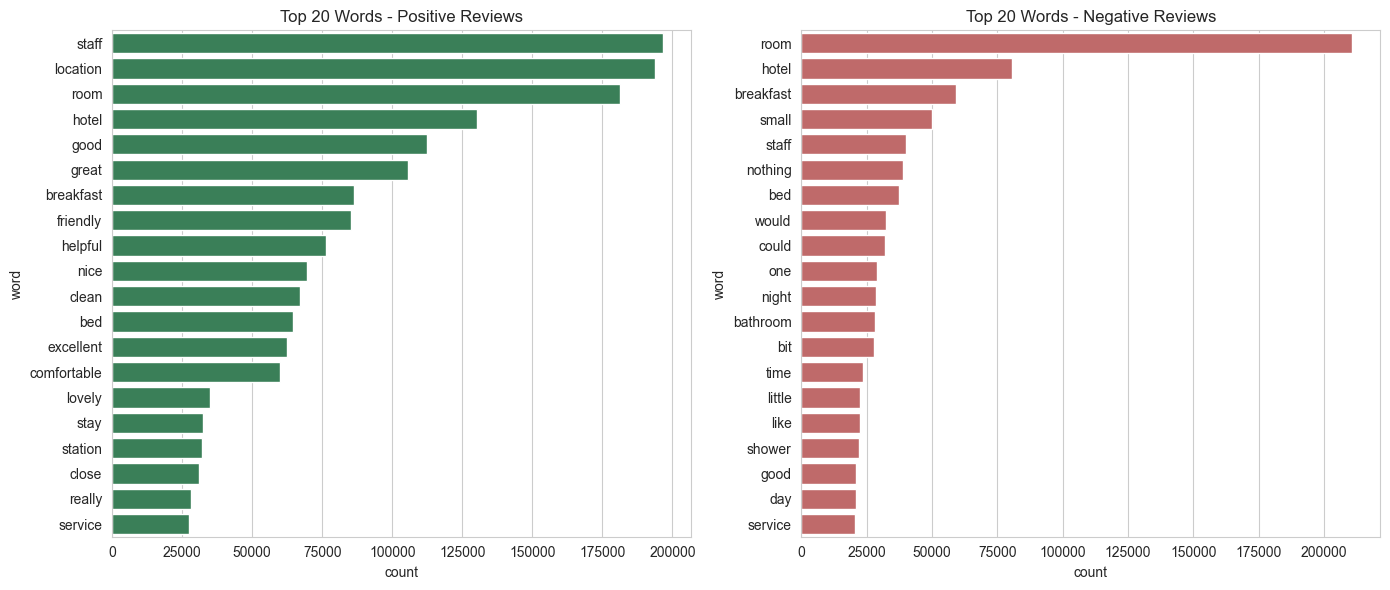

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=top_positive_words, x="count", y="word", ax=axes[0], color="seagreen")
axes[0].set_title("Top 20 Words - Positive Reviews")

sns.barplot(data=top_negative_words, x="count", y="word", ax=axes[1], color="indianred")
axes[1].set_title("Top 20 Words - Negative Reviews")

plt.tight_layout()
plt.savefig("eda_top_words_barchart.png", dpi=150)
plt.show()

Sentiment Analysis

In [46]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

import joblib


In [48]:
labelled_df = pd.read_csv("C:/Users/Acer/Desktop/Big_Data_Analysis_Project/hotel_reviews_cleaned1.csv")
labelled_df["Review_Date"] = pd.to_datetime(labelled_df["Review_Date"], errors="coerce")
labelled_df = labelled_df.dropna(subset=["review_text_clean"])
print("Shape:", labelled_df.shape)
print(labelled_df["sentiment"].value_counts())

Shape: (862955, 11)
sentiment
positive    478843
negative    384112
Name: count, dtype: int64


In [49]:
print(labelled_df["sentiment"].value_counts())

sentiment
positive    478843
negative    384112
Name: count, dtype: int64


In [50]:
SAMPLE_SIZE = 150000

sample_df = labelled_df.sample(n=SAMPLE_SIZE, random_state=42)
print("Sample shape:", sample_df.shape)
print(sample_df["sentiment"].value_counts())

Sample shape: (150000, 11)
sentiment
positive    83330
negative    66670
Name: count, dtype: int64


In [51]:
X = sample_df["review_text_clean"]
y = sample_df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 120000
Test size: 30000


In [52]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF train shape", X_train_tfidf.shape)
print("TF-IDF test shape", X_test_tfidf.shape)

TF-IDF train shape (120000, 10000)
TF-IDF test shape (30000, 10000)


In [53]:
start = time.time()
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_train_time = time.time() - start

nb_preds = nb_model.predict(X_test_tfidf)

print(f"Naive Bayes trained in {nb_train_time:.2f}s")
print("Accuracy:", accuracy_score(y_test, nb_preds))
print("Macro F1:", f1_score(y_test, nb_preds, average="macro"))
print(classification_report(y_test, nb_preds))

Naive Bayes trained in 0.90s
Accuracy: 0.9193666666666667
Macro F1: 0.9183417355921624
              precision    recall  f1-score   support

    negative       0.91      0.91      0.91     13334
    positive       0.93      0.93      0.93     16666

    accuracy                           0.92     30000
   macro avg       0.92      0.92      0.92     30000
weighted avg       0.92      0.92      0.92     30000



In [54]:
start = time.time()
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_model.fit(X_train_tfidf, y_train)
lr_train_time = time.time() - start

lr_preds = lr_model.predict(X_test_tfidf)

print(f"Logistic Regression trained in {lr_train_time:.2f}s")
print("Accuracy:", accuracy_score(y_test, lr_preds))
print("Macro F1:", f1_score(y_test, lr_preds, average="macro"))
print(classification_report(y_test, lr_preds))

Logistic Regression trained in 2.18s
Accuracy: 0.9286
Macro F1: 0.9279543428305939
              precision    recall  f1-score   support

    negative       0.90      0.94      0.92     13334
    positive       0.95      0.92      0.93     16666

    accuracy                           0.93     30000
   macro avg       0.93      0.93      0.93     30000
weighted avg       0.93      0.93      0.93     30000



In [55]:
start = time.time()
svm_model = LinearSVC(class_weight="balanced")
svm_model.fit(X_train_tfidf, y_train)
svm_train_time = time.time() - start

svm_preds = svm_model.predict(X_test_tfidf)

print(f"Linear SVM trained in {svm_train_time:.2f}s")
print("Accuracy:", accuracy_score(y_test, svm_preds))
print("Macro F1:", f1_score(y_test, svm_preds, average="macro"))
print(classification_report(y_test, svm_preds))

Linear SVM trained in 2.00s
Accuracy: 0.9261
Macro F1: 0.9253966086388568
              precision    recall  f1-score   support

    negative       0.90      0.93      0.92     13334
    positive       0.94      0.92      0.93     16666

    accuracy                           0.93     30000
   macro avg       0.92      0.93      0.93     30000
weighted avg       0.93      0.93      0.93     30000



In [56]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, nb_preds),
        accuracy_score(y_test, lr_preds),
        accuracy_score(y_test, svm_preds),
    ],
    "Macro F1": [
        f1_score(y_test, nb_preds, average="macro"),
        f1_score(y_test, lr_preds, average="micro"),
        f1_score(y_test, svm_preds, average="macro"),
    ],
    "Train Time (s)": [nb_train_time, lr_train_time, svm_train_time],
})

print(results)

                 Model  Accuracy  Macro F1  Train Time (s)
0          Naive Bayes  0.919367  0.918342        0.903231
1  Logistic Regression  0.928600  0.928600        2.184031
2           Linear SVM  0.926100  0.925397        1.996500


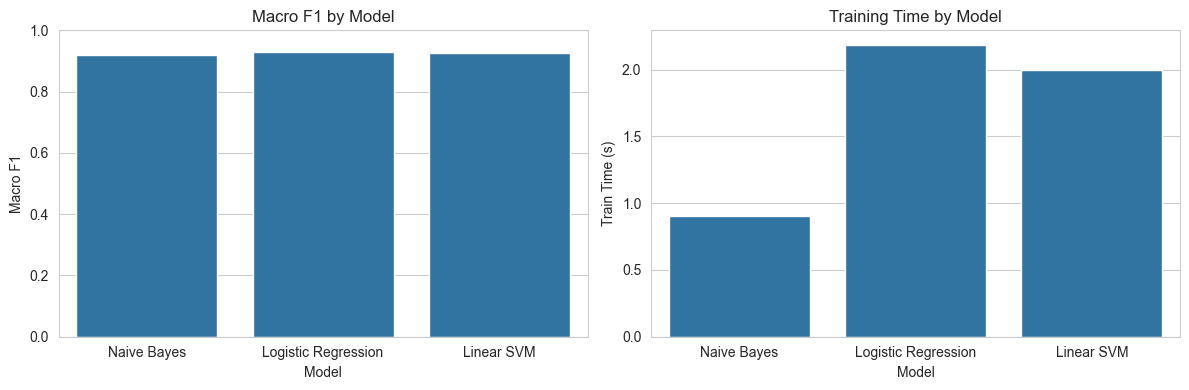

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.barplot(data=results, x="Model", y="Macro F1", ax=axes[0])
axes[0].set_title("Macro F1 by Model")
axes[0].set_ylim(0, 1)

sns.barplot(data=results, x="Model", y="Train Time (s)", ax=axes[1])
axes[1].set_title("Training Time by Model")

plt.tight_layout()
plt.savefig("sentiment_model_comparison.png", dpi=150)
plt.show()

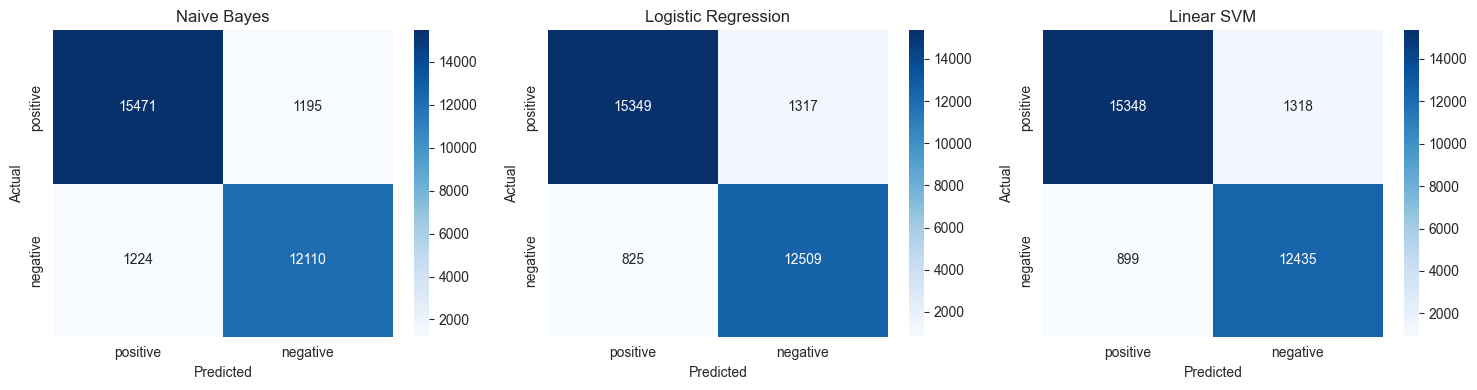

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, preds, name in zip(
    axes, [nb_preds, lr_preds, svm_preds],
    ["Naive Bayes", "Logistic Regression", "Linear SVM"]
):
    cm = confusion_matrix(y_test, preds, labels=["positive", "negative"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["positive", "negative"],
                yticklabels=["positive", "negative"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("sentiment_confusion_matrices.png", dpi=150)
plt.show()

In [59]:
best_model_name = "Logistic Regression"

In [60]:
final_model = LogisticRegression(max_iter=1000, class_weight="balanced")

Topic Modelling

In [61]:
pip install gensim --user

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

import gensim
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

import warnings
warnings.filterwarnings("ignore")

In [63]:
labelled_df = pd.read_csv("C:/Users/Acer/Desktop/Big_Data_Analysis_Project/hotel_reviews_cleaned1.csv")
labelled_df["Review_Date"] = pd.to_datetime(labelled_df["Review_Date"], errors="coerce")
labelled_df = labelled_df.dropna(subset=["review_text_clean"])
print("Shape:", labelled_df.shape)

Shape: (862955, 11)


In [64]:
EXTRA_STOPWORDS = {
    "hotel", "room", "rooms", "stay", "stayed", "staying",
    "night", "nights", "would", "could", "also", "us", "got", 
    "get", "one", "really", "very", "much", "even", "though"
}

def remove_extra_stopwords(text):
    return " ".join(w for w in text.split() if w not in EXTRA_STOPWORDS)

labelled_df["review_text_lda"] = labelled_df["review_text_clean"].apply(remove_extra_stopwords)

In [65]:
positive_texts = labelled_df.loc[labelled_df["sentiment"] == "positive", "review_text_lda"]
negative_texts = labelled_df.loc[labelled_df["sentiment"] == "negative", "review_text_lda"]

print("Positive texts:", len(positive_texts))
print("Negative texts:", len(negative_texts))

Positive texts: 478843
Negative texts: 384112


In [66]:
positive_tokens = [text.split() for text in positive_texts]
negative_tokens = [text.split() for text in negative_texts]

print("Example positive tokens:", positive_tokens[0])

Example positive tokens: ['park', 'outside', 'beautiful']


In [67]:
pos_dictionary = corpora.Dictionary(positive_tokens)
pos_dictionary.filter_extremes(no_below=5, no_above=0.5)
pos_corpus = [pos_dictionary.doc2bow(text) for text in positive_tokens]

print("Positive dictionary size:", len(pos_dictionary))

Positive dictionary size: 11306


In [68]:
topic_range = range(5, 16, 2)
pos_coherence_scores = []

for k in topic_range:
    lda_temp = LdaModel(
        corpus=pos_corpus, id2word=pos_dictionary, num_topics=k,
        random_state=42, passes=5, chunksize=2000
    )
    coherence_model = CoherenceModel(
        model=lda_temp, texts=positive_tokens, dictionary=pos_dictionary, coherence="c_v"
    )
    score = coherence_model.get_coherence()
    pos_coherence_scores.append(score)
    print(f"k={k}, coherence={score:.4f}")

k=5, coherence=0.6289
k=7, coherence=0.6272
k=9, coherence=0.6421
k=11, coherence=0.6443
k=13, coherence=0.6455
k=15, coherence=0.6327


In [69]:
import random
random.seed(42)
sample_idx = random.sample(range(len(pos_corpus)), 50000)
pos_corpus_sample = [pos_corpus[i] for i in sample_idx]
pos_tokens_sample = [positive_tokens[i] for i in sample_idx]

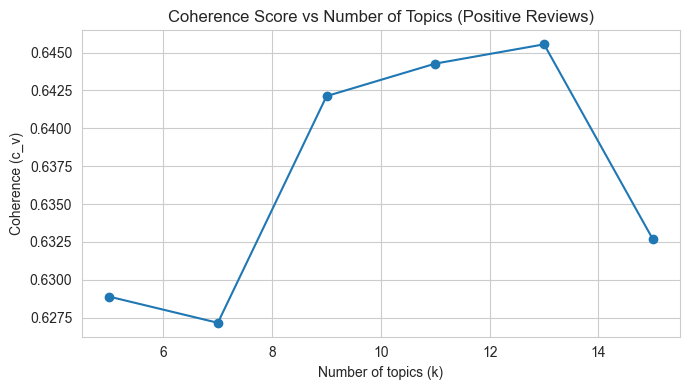

In [70]:
plt.figure(figsize=(7, 4))
plt.plot(list(topic_range), pos_coherence_scores, marker="o")
plt.title("Coherence Score vs Number of Topics (Positive Reviews)")
plt.xlabel("Number of topics (k)")
plt.ylabel("Coherence (c_v)")
plt.tight_layout()
plt.savefig("lda_coherence_positive.png", dpi=150)
plt.show()

In [71]:
print(len(list(topic_range)))
print(len(pos_coherence_scores))
print(pos_coherence_scores)

6
6
[np.float64(0.6288870759055074), np.float64(0.6271566960320608), np.float64(0.6421258839021549), np.float64(0.6442729333178681), np.float64(0.6455442984427109), np.float64(0.6326785410346332)]


In [72]:
BEST_K_POSITIVE = 13 

pos_lda_model = LdaModel(
    corpus=pos_corpus, id2word=pos_dictionary, num_topics=BEST_K_POSITIVE,
    random_state=42, passes=10, chunksize=2000
)

for idx, topic in pos_lda_model.print_topics(num_words=10):
    print(f"Topic {idx}: {topic}\n")

Topic 0: 0.083*"view" + 0.044*"bar" + 0.039*"staff" + 0.029*"lovely" + 0.028*"beautiful" + 0.025*"new" + 0.025*"amazing" + 0.022*"decor" + 0.021*"feel" + 0.020*"help"

Topic 1: 0.174*"everything" + 0.163*"perfect" + 0.085*"amazing" + 0.050*"loved" + 0.039*"place" + 0.034*"spa" + 0.024*"needed" + 0.024*"style" + 0.022*"experience" + 0.021*"love"

Topic 2: 0.130*"service" + 0.104*"staff" + 0.096*"excellent" + 0.060*"food" + 0.032*"facility" + 0.029*"restaurant" + 0.028*"desk" + 0.027*"overall" + 0.027*"quality" + 0.026*"cleanliness"

Topic 3: 0.369*"great" + 0.353*"location" + 0.037*"excellent" + 0.024*"design" + 0.021*"central" + 0.018*"facility" + 0.017*"fantastic" + 0.013*"convenient" + 0.009*"bike" + 0.009*"across"

Topic 4: 0.171*"bed" + 0.138*"comfortable" + 0.096*"clean" + 0.055*"bathroom" + 0.053*"comfy" + 0.048*"nice" + 0.038*"big" + 0.035*"spacious" + 0.032*"modern" + 0.028*"large"

Topic 5: 0.054*"free" + 0.031*"check" + 0.024*"day" + 0.016*"drink" + 0.015*"made" + 0.014*"car"

In [73]:
print("pos_lda_model topics:", pos_lda_model.num_topics)
print("pos_corpus size:", len(pos_corpus))
print("positive_tokens size:", len(positive_tokens))

pos_lda_model topics: 13
pos_corpus size: 478843
positive_tokens size: 478843


In [74]:
negative_tokens = [text.split() for text in negative_texts]
print("Example negative tokens:", negative_tokens[0])

Example negative tokens: ['angry', 'made', 'post', 'available', 'via', 'possible', 'site', 'use', 'planing', 'trip', 'make', 'mistake', 'booking', 'place', 'made', 'booking', 'via', 'booking', 'com', 'july', 'upon', 'arrival', 'placed', 'small', 'floor', 'turned', 'booked', 'specially', 'reserved', 'level', 'duplex', 'big', 'window', 'high', 'ceiling', 'mind', 'broken', 'window', 'closed', 'hello', 'rain', 'mini', 'fridge', 'contained', 'sort', 'bio', 'weapon', 'least', 'guessed', 'smell', 'intimately', 'asked', 'change', 'explaining', 'time', 'booked', 'duplex', 'btw', 'cost', 'simple', 'double', 'way', 'volume', 'due', 'high', 'ceiling', 'offered', 'next', 'day', 'check', 'next', 'day', 'clock', 'order', 'waned', 'best', 'way', 'begin', 'holiday', 'wait', 'till', 'order', 'check', 'new', 'wonderful', 'waist', 'time', 'wanted', 'peaceful', 'internal', 'garden', 'view', 'big', 'window', 'tired', 'waiting', 'placed', 'belonging', 'rushed', 'city', 'evening', 'turned', 'constant', 'noise

In [75]:
neg_dictionary = corpora.Dictionary(negative_tokens)
neg_dictionary.filter_extremes(no_below=5, no_above=0.5)
neg_corpus = [neg_dictionary.doc2bow(text) for text in negative_tokens]

print("Negative dictionary size:", len(neg_dictionary))

Negative dictionary size: 12705


In [76]:
neg_coherence_scores = []

for k in topic_range:
    lda_temp = LdaModel(
        corpus = neg_corpus, id2word=neg_dictionary, num_topics=k,
        random_state=42, passes=5, chunksize=2000
    )
    coherence_model = CoherenceModel(
        model=lda_temp, texts=negative_tokens, dictionary=neg_dictionary, coherence="c_v"
    )
    score = coherence_model.get_coherence()
    neg_coherence_scores.append(score)
    print(f"k={k}, coherence={score:.4f}")


k=5, coherence=0.6555
k=7, coherence=0.6832
k=9, coherence=0.7213
k=11, coherence=0.7134
k=13, coherence=0.7034
k=15, coherence=0.6957


In [78]:
BEST_K_NEGATIVE = 9

neg_lda_model = LdaModel(
    corpus=neg_corpus, id2word=neg_dictionary, num_topics=BEST_K_NEGATIVE,
    random_state=42, passes=10, chunksize=5000, eval_every=None
)
neg_lda_model.save("lda_negative_model.model")

print("Number of topics:", neg_lda_model.num_topics) 
for idx, topic in neg_lda_model.print_topics(num_words=10):
    print(f"Topic {idx}: {topic}\n")

Number of topics: 9
Topic 0: 0.085*"bed" + 0.072*"small" + 0.029*"parking" + 0.021*"double" + 0.017*"two" + 0.016*"hard" + 0.015*"pillow" + 0.015*"car" + 0.014*"single" + 0.014*"bit"

Topic 1: 0.114*"breakfast" + 0.036*"bar" + 0.027*"price" + 0.026*"coffee" + 0.025*"expensive" + 0.023*"food" + 0.023*"restaurant" + 0.021*"service" + 0.018*"tea" + 0.017*"poor"

Topic 2: 0.055*"bathroom" + 0.044*"shower" + 0.024*"old" + 0.020*"small" + 0.018*"need" + 0.016*"toilet" + 0.015*"clean" + 0.014*"dirty" + 0.014*"bath" + 0.014*"water"

Topic 3: 0.256*"nothing" + 0.067*"everything" + 0.043*"bad" + 0.036*"great" + 0.034*"like" + 0.032*"metro" + 0.032*"thing" + 0.023*"perfect" + 0.019*"liked" + 0.018*"complaint"

Topic 4: 0.032*"check" + 0.030*"wifi" + 0.023*"time" + 0.018*"pay" + 0.015*"day" + 0.013*"free" + 0.013*"hour" + 0.012*"card" + 0.012*"took" + 0.011*"long"

Topic 5: 0.029*"noise" + 0.027*"noisy" + 0.025*"floor" + 0.025*"view" + 0.022*"door" + 0.018*"window" + 0.017*"outside" + 0.017*"stree

In [79]:
print("Positive topics:", pos_lda_model.num_topics)
for idx, topic in pos_lda_model.print_topics(num_words=8):
    print(f"Topic {idx}: {topic}\n")

Positive topics: 13
Topic 0: 0.083*"view" + 0.044*"bar" + 0.039*"staff" + 0.029*"lovely" + 0.028*"beautiful" + 0.025*"new" + 0.025*"amazing" + 0.022*"decor"

Topic 1: 0.174*"everything" + 0.163*"perfect" + 0.085*"amazing" + 0.050*"loved" + 0.039*"place" + 0.034*"spa" + 0.024*"needed" + 0.024*"style"

Topic 2: 0.130*"service" + 0.104*"staff" + 0.096*"excellent" + 0.060*"food" + 0.032*"facility" + 0.029*"restaurant" + 0.028*"desk" + 0.027*"overall"

Topic 3: 0.369*"great" + 0.353*"location" + 0.037*"excellent" + 0.024*"design" + 0.021*"central" + 0.018*"facility" + 0.017*"fantastic" + 0.013*"convenient"

Topic 4: 0.171*"bed" + 0.138*"comfortable" + 0.096*"clean" + 0.055*"bathroom" + 0.053*"comfy" + 0.048*"nice" + 0.038*"big" + 0.035*"spacious"

Topic 5: 0.054*"free" + 0.031*"check" + 0.024*"day" + 0.016*"drink" + 0.015*"made" + 0.014*"car" + 0.013*"upgrade" + 0.013*"early"

Topic 6: 0.281*"staff" + 0.146*"friendly" + 0.133*"helpful" + 0.053*"location" + 0.042*"clean" + 0.034*"breakfast" 

In [81]:
positive_topic_labels = {
    0: "View & Ambiance",
    1: "Overall Experience",
    2: "Service & Facilities",
    3: "Location (general)",
    4: "Room Comfort",
    5: "Extras/Perks",
    6: "Staff Friendliness",
    7: "Recommendation/Repeat Visit", 
    8: "Value for Money", 
    9: "Breakfast Quality",
    10: "Minor/Mixed Remarks",
    11: "Location - Nearby Amenities",
    12: "Location - Transit Access", 
}

negative_topic_labels = {
    0: "Bed Size/Comfort & Parking",
    1: "Breakfast, Food & Price", 
    2: "Bathroom Condition", 
    3: "No Complaint (filler)",
    4: "Check-in, WiFi & Payment",
    5: "Noise",
    6: "Heating/AC & Maintenance",
    7: "Staff & Booking Issues",
    8: "Location (distance)"
}

In [83]:
def dominant_topic(model, bow):
    probs = model.get_document_topics(bow, minimum_probability=0.0)
    return max(probs, key=lambda x:x[1])[0]

pos_dominant = [dominant_topic(pos_lda_model, doc) for doc in pos_corpus]
neg_dominant = [dominant_topic(neg_lda_model, doc) for doc in neg_corpus]

print(len(pos_dominant), len(neg_dominant))

478843 384112


In [84]:
positive_idx = labelled_df.index[labelled_df["sentiment"] == "positive"]
negative_idx = labelled_df.index[labelled_df["sentiment"] == "negative"]

#these must match, otherwise topics would be signed to the wrong rows
assert len(positive_idx) == len(pos_dominant), "positive length mismatch"
assert len(negative_idx) == len(neg_dominant), "negative length mismatch"

labelled_df.loc[positive_idx, "topic_id"] = pos_dominant
labelled_df.loc[negative_idx, "topic_id"] = neg_dominant

labelled_df.loc[positive_idx, "topic_label"] = labelled_df.loc[positive_idx, "topic_id"].map(positive_topic_labels)
labelled_df.loc[negative_idx, "topic_label"] = labelled_df.loc[negative_idx, "topic_id"].map(negative_topic_labels)

print(labelled_df.groupby(["sentiment", "topic_label"]). size())


sentiment  topic_label                
negative   Bathroom Condition             52024
           Bed Size/Comfort & Parking     51407
           Breakfast, Food & Price        64388
           Check-in, WiFi & Payment       35971
           Heating/AC & Maintenance       22537
           Location (distance)            25269
           No Complaint (filler)          41800
           Noise                          40585
           Staff & Booking Issues         50131
positive   Breakfast Quality              25734
           Extras/Perks                   26885
           Location (general)             53512
           Location - Nearby Amenities    37174
           Location - Transit Access      52059
           Minor/Mixed Remarks            14635
           Overall Experience             16707
           Recommendation/Repeat Visit    17272
           Room Comfort                   50903
           Service & Facilities           23833
           Staff Friendliness             96394
 

In [85]:
labelled_df.to_parquet("hotel_reviews_with_topics.parquet", index=False)
labelled_df.to_csv("hotel_reviews_with_topics.csv", index=False)
print("Saved:", labelled_df.shape)

Saved: (862955, 14)


In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [87]:
df = pd.read_csv("hotel_reviews_with_topics.csv")
df["Review_Date"] = pd.to_datetime(df["Review_Date"], errors="coerce")

In [88]:
df = df.dropna(subset=["topic_label"])
print(df["sentiment"].value_counts())
print(df.groupby("sentiment")["topic_label"].nunique)

sentiment
positive    478843
negative    384112
Name: count, dtype: int64
<bound method SeriesGroupBy.nunique of <pandas.core.groupby.generic.SeriesGroupBy object at 0x0000014EA91E59D0>>


In [89]:
print(df.groupby(["sentiment", "topic_label"]).size())

sentiment  topic_label                
negative   Bathroom Condition             52024
           Bed Size/Comfort & Parking     51407
           Breakfast, Food & Price        64388
           Check-in, WiFi & Payment       35971
           Heating/AC & Maintenance       22537
           Location (distance)            25269
           No Complaint (filler)          41800
           Noise                          40585
           Staff & Booking Issues         50131
positive   Breakfast Quality              25734
           Extras/Perks                   26885
           Location (general)             53512
           Location - Nearby Amenities    37174
           Location - Transit Access      52059
           Minor/Mixed Remarks            14635
           Overall Experience             16707
           Recommendation/Repeat Visit    17272
           Room Comfort                   50903
           Service & Facilities           23833
           Staff Friendliness             96394
 

In [92]:
theme_map = {
    # --- positive-model labels ---
    "Location (general)": "Location",
    "Location - Transit Access": "Location",
    "Location - Nearby Amenities": "Location",
    "Staff Friendliness": "Staff & Service",
    "Service & Facilities": "Staff & Service",
    "Room Comfort": "Room",
    "Breakfast Quality": "Breakfast & Food",
    "Value for Money": "Value & Price",
    "View & Ambiance": "Ambiance & Facilities",
    "Extras/Perks": "Ambiance & Facilities",
    "Overall Experience": "General Praise",
    "Recommendation/Repeat Visit": "General Praise",
    "Minor/Mixed Remarks": "Other",

    # ---negative-model labels ---
    "Bed Size/Comfort & Parking": "Room",
    "Bathroom Condition": "Room",
    "Breakfast, Food & Price": "Breakfast & Food",
    "Check-in, WiFi & Payment": "Check-in & Payments",
    "Noise": "Noise",
    "Heating/AC & Maintenance": "Ambiance & Facilities",
    "Staff & Booking Issues": "Staff & Service",
    "Location (distance)": "Location",
    "No Complaint (filler)": "No Complaint",
}

df["theme"] = df["topic_label"].map(theme_map).fillna(df["topic_label"])

before = len(df)
df = df[df["theme"] != "No Complaint"]
print(f"Removed {before - len(df)} filler rows")

print(df.groupby(["sentiment", "theme"]).size())

Removed 0 filler rows
sentiment  theme                
negative   Ambiance & Facilities     22537
           Breakfast & Food          64388
           Check-in & Payments       35971
           Location                  25269
           Noise                     40585
           Room                     103431
           Staff & Service           50131
positive   Ambiance & Facilities     55216
           Breakfast & Food          25734
           General Praise            33979
           Location                 142745
           Other                     14635
           Room                      50903
           Staff & Service          120227
           Value & Price             35404
dtype: int64


In [93]:
pos_prev = df[df["sentiment"] == "positive"]["theme"].value_counts(normalize=True) * 100
neg_prev = df[df["sentiment"] == "negative"]["theme"].value_counts(normalize=True) * 100

print("Positive %:\n", pos_prev.round(2))
print("\nNegative %:\n", neg_prev.round(2))

Positive %:
 theme
Location                 29.81
Staff & Service          25.11
Ambiance & Facilities    11.53
Room                     10.63
Value & Price             7.39
General Praise            7.10
Breakfast & Food          5.37
Other                     3.06
Name: proportion, dtype: float64

Negative %:
 theme
Room                     30.22
Breakfast & Food         18.81
Staff & Service          14.64
Noise                    11.86
Check-in & Payments      10.51
Location                  7.38
Ambiance & Facilities     6.58
Name: proportion, dtype: float64


In [94]:
comparison = pd.DataFrame({"Positive %": pos_prev, "Negative %": neg_prev}).fillna(0)
comparison["Difference (Neg - Pos)"] = comparison["Negative %"] - comparison["Positive %"]
comparison["Ratio (Neg / Pos)"] = comparison["Negative %"]/ comparison["Positive %"].replace(0, float("nan"))
comparison = comparison.sort_values("Difference (Neg - Pos)", ascending=False)
comparison.round(2)

,Positive %,Negative %,Difference (Neg - Pos),Ratio (Neg / Pos)
theme,,,,
Room,10.63,30.22,19.59,2.84
Breakfast & Food,5.37,18.81,13.44,3.50
Noise,0.00,11.86,11.86,NaN
Check-in & Payments,0.00,10.51,10.51,NaN
Other,3.06,0.00,-3.06,0.00
Ambiance & Facilities,11.53,6.58,-4.95,0.57
General Praise,7.10,0.00,-7.10,0.00
Value & Price,7.39,0.00,-7.39,0.00
Staff & Service,25.11,14.64,-10.46,0.58


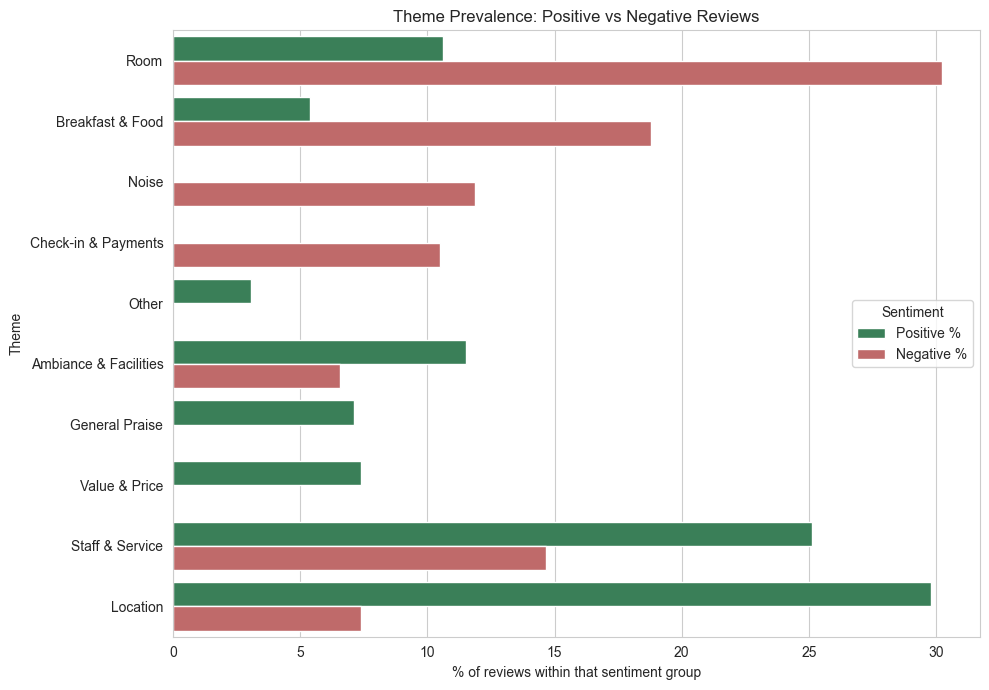

In [95]:
plot_df = comparison[["Positive %", "Negative %"]].reset_index()
plot_df = plot_df.rename(columns={"index": "Theme", "theme":"Theme"})
melted = plot_df.melt(id_vars="Theme", var_name="Sentiment", value_name="Percentage")

plt.figure(figsize=(10,7))
sns.barplot(data=melted, y="Theme", x="Percentage", hue="Sentiment",
            palette={"Positive %": "seagreen", "Negative %": "indianred"})
plt.title("Theme Prevalence: Positive vs Negative Reviews")
plt.xlabel("% of reviews within that sentiment group")
plt.tight_layout()
plt.savefig("combines_theme_sentiment_comparison.png", dpi=150)
plt.show()

In [96]:
print("Over-represented in NEGATIVE reviews (hygiene factors):")
print(comparison.head(5).round(2))
print("\nOver-represented in POSITIVE reviews (satisfaction drivers):")
print(comparison.tail(5).iloc[::-1].round(2))


Over-represented in NEGATIVE reviews (hygiene factors):
                     Positive %  Negative %  Difference (Neg - Pos)  Ratio (Neg / Pos)
theme                                                                                 
Room                      10.63       30.22                   19.59               2.84
Breakfast & Food           5.37       18.81                   13.44               3.50
Noise                      0.00       11.86                   11.86                NaN
Check-in & Payments        0.00       10.51                   10.51                NaN
Other                      3.06        0.00                   -3.06               0.00

Over-represented in POSITIVE reviews (satisfaction drivers):
                       Positive %  Negative %  Difference (Neg - Pos)  Ratio (Neg / Pos)
theme                                                                                   
Location                    29.81        7.38                  -22.43               0.25
Staff 

In [98]:
cols = ["Hotel_Name", "Country", "Review_Date", "Reviewer_Score",
        "Reviewer_Nationality", "sentiment", "predicted_sentiment", 
        "topic_label", "theme", "review_length_words", "review_year", "review_month"]

cols = [ c for c in cols if c in df.columns]

df[cols].to_csv("hotel_reviews_powerbi.csv", index=False)
print("Saved:", df[cols].shape)
print(cols)

Saved: (821155, 11)
['Hotel_Name', 'Country', 'Review_Date', 'Reviewer_Score', 'Reviewer_Nationality', 'sentiment', 'topic_label', 'theme', 'review_length_words', 'review_year', 'review_month']
